# Task 4 (Monocular Depth Estimation) — Rank 1 Commercial Model Test: `DA3-SMALL`

**Objective:** Verify **`depth-anything/DA3-SMALL`** (`ByteDance-Seed/Depth-Anything-3`, **Apache-2.0**) end-to-end as a commercial replacement for `yolo26m-depth-736x1280.onnx` in `f:\IRIS\surveillance-new`'s Proximity pipeline ([perception/modules/proximity/depth.py](file:///f:/IRIS/surveillance-new/perception/modules/proximity/depth.py)):
1. Route **all** HuggingFace downloads & exported ONNX artifacts strictly into **`notebooks/downloads/`**.
2. Inspect `depth.py` contracts programmatically (`DepthModel`, `letterbox`, static `(H, W)` input shape, `[0, 1]` RGB normalization, positive distance polarity `near < far`, `depth_gap`, `colourise`, `DepthWorker`, `ensure_on_gpu`).
3. Load official Apache-2.0 `depth-anything/DA3-SMALL` (`0.08B` / ~26M depth-net params) via `depth_anything_3.cfg.create_object` (zero heavy Gaussian/COLMAP deps), run PyTorch CUDA inference, and check distance polarity (`near < far`).
4. Export **`da3-small-504x896.onnx`** (`PATCH_SIZE=14` divisible 16:9) with **baked ImageNet normalization** and **ONNX-safe 2D RoPE `meshgrid`** (replacing `aten::cartesian_prod`).
5. Drop `da3-small-504x896.onnx` straight into **unmodified IRIS `DepthModel`, `ensure_on_gpu`, `DepthWorker`, `depth_gap`, and `colourise`**, verifying `PT vs ORT` parity, asynchronous `DepthWorker` execution, GPU latency across 60 `calib_images`, and near/far `depth_gap` calibration.


In [1]:
import json
import os
import sys
import time
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "perception" / "modules" / "proximity" / "depth.py").is_file():
            return p
    raise FileNotFoundError("Could not locate IRIS repository root from " + str(start))

REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Route ALL HF downloads & ONNX exports into notebooks/downloads/
DOWNLOADS_DIR = REPO_ROOT / "notebooks" / "downloads"
MODELS_CACHE_DIR = DOWNLOADS_DIR / "models_cache"
ONNX_EXPORT_DIR = DOWNLOADS_DIR / "onnx_exports"
MODELS_CACHE_DIR.mkdir(parents=True, exist_ok=True)
ONNX_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(MODELS_CACHE_DIR / "hf")
os.environ["TORCH_HOME"] = str(MODELS_CACHE_DIR / "torch")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import HfApi, hf_hub_download
from omegaconf import OmegaConf
from safetensors.torch import load_file

import depth_anything_3.model.dinov2.layers.rope as rope_mod
from depth_anything_3.cfg import create_object

from perception.modules.proximity.camera import DepthRequest
from perception.modules.proximity.depth import (
    DepthModel,
    DepthWorker,
    colourise,
    depth_gap,
    ensure_on_gpu,
    letterbox,
)
from perception.modules.proximity.shapes import Blob

CALIB_DIR = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images"
calib_images = sorted(CALIB_DIR.glob("*.jpg"))

print(f"Repo root          : {REPO_ROOT}")
print(f"Downloads hub      : {DOWNLOADS_DIR.relative_to(REPO_ROOT)}")
print(f"PyTorch            : {torch.__version__} | CUDA: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"ONNX / ORT         : {onnx.__version__} / {ort.__version__} | providers={ort.get_available_providers()}")
print(f"Local calib frames : {len(calib_images)} JPEGs")


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\cfg.py:25: UserWarning: register_new_resolver() is deprecated and will be removed in a future release.
Use register_resolver() instead.
See https://github.com/hydra-ecosystem/omegaconf/issues/426 for migration instructions.

  OmegaConf.register_new_resolver("eval", eval)
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Repo root          : F:\IRIS\surveillance-new
Downloads hub      : notebooks\downloads


PyTorch            : 2.14.1+cu130 | CUDA: True (Quadro RTX 3000)
ONNX / ORT         : 1.23.2 / 1.32.0 | providers=['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Local calib frames : 60 JPEGs


## 1. License Verification & PyTorch `DA3-SMALL` Depth Polarity Check

First confirm on HuggingFace that **`depth-anything/DA3-SMALL`** carries an **`apache-2.0`** license tag (and note that community bundle `SpatialHub/depth-anything-3-onnx` is tagged `cc-by-nc-4.0`, so exporting directly from `depth-anything/DA3-SMALL` preserves commercial safety). Then run PyTorch inference on `calib_images` and verify depth polarity (`near foreground < far background`).


In [2]:
api = HfApi()
da3_info = api.model_info("depth-anything/DA3-SMALL")
print(f"HF repo license tag  : {da3_info.card_data.license}")
assert da3_info.card_data.license == "apache-2.0"

cfg_path = hf_hub_download("depth-anything/DA3-SMALL", "config.json")
weights_path = hf_hub_download("depth-anything/DA3-SMALL", "model.safetensors")

cfg = json.loads(Path(cfg_path).read_text(encoding="utf-8"))["config"]
da3_net = create_object(OmegaConf.create(cfg))
state = {k.removeprefix("model."): v for k, v in load_file(weights_path).items()}
missing, unexpected = da3_net.load_state_dict(state, strict=False)
print(f"Loaded DA3-SMALL     : missing={len(missing)} (unused aux sky/ray heads), unexpected={len(unexpected)}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
TARGET_HW = (504, 896)  # Exact 16:9 multiple of DA3 PATCH_SIZE=14 (36x64 patches)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
da3_net = da3_net.to(device).eval()
mean_t = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)

SAMPLE_NAMES = ["frame_00014.jpg", "frame_00041.jpg", "frame_00051.jpg", "frame_00055.jpg"]
SAMPLE_PATHS = [CALIB_DIR / n for n in SAMPLE_NAMES]

def run_da3_pytorch(bgr: np.ndarray, hw=TARGET_HW) -> np.ndarray:
    x_lb, s, top, left = letterbox(bgr, hw)
    t = torch.from_numpy(x_lb).to(device)
    t_norm = ((t - mean_t) / std_t).unsqueeze(1)  # (1, 1, 3, H, W)
    with torch.no_grad():
        feats, _ = da3_net.backbone(t_norm, cam_token=None, export_feat_layers=[])
        out = da3_net._process_depth_head(feats, hw[0], hw[1])
    d = out["depth"][0, 0].cpu().numpy()
    h, w = bgr.shape[:2]
    return d[top:top + int(round(h * s)), left:left + int(round(w * s))]

# Warmup & check polarity on 4 surveillance frames
_ = run_da3_pytorch(cv2.imread(str(SAMPLE_PATHS[0])))
if torch.cuda.is_available():
    torch.cuda.synchronize()

pt_depths = {}
for p in SAMPLE_PATHS:
    bgr = cv2.imread(str(p))
    t0 = time.perf_counter()
    d = run_da3_pytorch(bgr)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) * 1000.0
    top_med = float(np.median(d[:int(d.shape[0] * 0.2), :]))
    bot_med = float(np.median(d[int(d.shape[0] * 0.8):, :]))
    pt_depths[p.name] = (bgr, d, ms)
    print(f"  {p.name:15s} | depth={d.shape} | range=({d.min():.3f}, {d.max():.3f}) | "
          f"top20%(far)={top_med:.3f} vs bot20%(near)={bot_med:.3f} | {ms:5.1f} ms")
    assert top_med > bot_med and d.min() > 0, "Expected positive distance polarity (far > near)"


HF repo license tag  : apache-2.0


[INFO ] using MLP layer as FFN


Loaded DA3-SMALL     : missing=6 (unused aux sky/ray heads), unexpected=0


  frame_00014.jpg | depth=(504, 756) | range=(0.271, 5.810) | top20%(far)=0.784 vs bot20%(near)=0.693 | 160.0 ms
  frame_00041.jpg | depth=(504, 756) | range=(0.281, 6.664) | top20%(far)=0.725 vs bot20%(near)=0.696 | 154.5 ms


  frame_00051.jpg | depth=(504, 756) | range=(0.263, 5.948) | top20%(far)=0.781 vs bot20%(near)=0.694 | 162.7 ms
  frame_00055.jpg | depth=(504, 756) | range=(0.292, 5.637) | top20%(far)=0.731 vs bot20%(near)=0.698 | 156.8 ms


## 2. IRIS Codebase Audit (`perception/modules/proximity/depth.py`) & ONNX Export (`da3-small-504x896.onnx`)

`DepthModel` ([depth.py#L62-L77](file:///f:/IRIS/surveillance-new/perception/modules/proximity/depth.py#L62-L77)) expects:
1. Static integer spatial dimensions in ONNX input (`int(inp.shape[2]), int(inp.shape[3])` — dynamic spatial shapes crash startup).
2. Unnormalized `[0, 1]` RGB float32 `[1, 3, H, W]` from `letterbox(..., PAD=114)`.
3. Single output reshaped directly via `[0].reshape(self.hw)` as positive depth (`near < far`).

Note two repo compatibility traps solved cleanly at export time:
- **RoPE `aten::cartesian_prod`:** `depth_anything_3/model/dinov2/layers/rope.py#L56` uses `torch.cartesian_prod`, which TorchScript ONNX opset 17 does not export directly. Replacing it with `torch.meshgrid(..., indexing='ij')` during `is_in_onnx_export()` lowers cleanly to standard ONNX ops.
- **ImageNet Norm + Input Resolution:** We bake `(x - mean) / std` inside `IrisDA3DepthWrapper`, strip `cam_enc`/`cam_dec`, and use static `504×896` (`36×64` patches of `14`), dropping straight into **unmodified** `DepthModel`.


In [3]:
# Verify actual IRIS DepthModel expectations cleanly
depth_src = (REPO_ROOT / "perception" / "modules" / "proximity" / "depth.py").read_text(encoding="utf-8")
assert "(int(inp.shape[2]), int(inp.shape[3]))" in depth_src
assert "self.session.run(None, {self.input: x})[0].reshape(self.hw)" in depth_src
assert "((hi - depth) * (255.0 / (hi - lo)))" in depth_src

# ONNX-friendly cartesian_prod patch for 2D RoPE
_orig_cp = torch.cartesian_prod
def _onnx_cartesian_prod(*tensors):
    if len(tensors) == 2 and torch.onnx.is_in_onnx_export():
        yy, xx = torch.meshgrid(tensors[0], tensors[1], indexing="ij")
        return torch.stack([yy, xx], dim=-1).reshape(-1, 2)
    return _orig_cp(*tensors)
rope_mod.torch.cartesian_prod = _onnx_cartesian_prod

class IrisDA3DepthWrapper(nn.Module):
    def __init__(self, net: nn.Module):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_norm = ((x - self.mean) / self.std).unsqueeze(1)  # [1, 1, 3, H, W]
        feats, _ = self.net.backbone(x_norm, cam_token=None, export_feat_layers=[])
        out = self.net._process_depth_head(feats, x.shape[-2], x.shape[-1])
        return out["depth"][:, 0]  # [1, H, W]

da3_cpu = da3_net.cpu().eval()
wrapper = IrisDA3DepthWrapper(da3_cpu).eval()
ONNX_DA3_PATH = ONNX_EXPORT_DIR / "da3-small-504x896.onnx"
dummy = torch.zeros(1, 3, TARGET_HW[0], TARGET_HW[1], dtype=torch.float32)

t0 = time.perf_counter()
torch.onnx.export(
    wrapper, dummy, str(ONNX_DA3_PATH),
    input_names=["images"], output_names=["depth"],
    export_params=True, keep_initializers_as_inputs=False,
    do_constant_folding=True, opset_version=17, dynamo=False,
)
export_s = time.perf_counter() - t0
if torch.cuda.is_available():
    torch.cuda.empty_cache()

om = onnx.load(str(ONNX_DA3_PATH))
onnx.checker.check_model(om)
custom_domains = {n.domain for n in om.graph.node if n.domain}
in_dims = [d.dim_value for d in om.graph.input[0].type.tensor_type.shape.dim]
out_dims = [d.dim_value for d in om.graph.output[0].type.tensor_type.shape.dim]

print(f"Exported ONNX   : {ONNX_DA3_PATH.relative_to(REPO_ROOT)} ({ONNX_DA3_PATH.stat().st_size/1e6:.2f} MB in {export_s:.1f}s)")
print(f"Input / Output  : {in_dims} -> {out_dims} (static HW verified for IRIS DepthModel)")
print(f"Custom domains  : {custom_domains}")
assert in_dims == [1, 3, TARGET_HW[0], TARGET_HW[1]] and out_dims == [1, TARGET_HW[0], TARGET_HW[1]]
assert not custom_domains


C:\Users\Maha Mamdouh\AppData\Local\Temp\ipykernel_25136\4210266074.py:35: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\layers\patch_embed.py:73: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  H % patch_H == 0
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\layers\patch_embed

F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\vision_transformer.py:314: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if self.alt_start != -1 and (i == self.alt_start - 1) and x.shape[1] >= THRESH_FOR_REF_SELECTION and kwargs.get("cam_token", None) is None:
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\layers\rope.py:174: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert tokens.size(-1) % 2 == 0, "Feature dimension must be even"
F:\IRIS\surveilla

F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\vision_transformer.py:344: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if x.shape[1] >= THRESH_FOR_REF_SELECTION and self.alt_start != -1 and 'b_idx' in locals():


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\vision_transformer.py:383: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if outputs[0][1].shape[-1] == self.embed_dim:
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dinov2\vision_transformer.py:385: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  elif outputs[0][1].shape[-1] == (self.embed_dim * 2):
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dualdpt.py:183: TracerWar

F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\utils\head_utils.py:222: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if total > INT_MAX:


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\utils\head_utils.py:217: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  size = (int(x.shape[-2] * scale_factor), int(x.shape[-1] * scale_factor))


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dualdpt.py:233: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  h_out = int(ph * self.patch_size / self.down_ratio)
F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\depth_anything_3\model\dualdpt.py:234: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  w_out = int(pw * self.patch_size / self.down_ratio)


Exported ONNX   : notebooks\downloads\onnx_exports\da3-small-504x896.onnx (100.54 MB in 6.4s)
Input / Output  : [1, 3, 504, 896] -> [1, 504, 896] (static HW verified for IRIS DepthModel)
Custom domains  : set()


## 3. Drop-In Validation via Unmodified IRIS `DepthModel`, `DepthWorker`, `depth_gap` & `colourise`

Test `da3-small-504x896.onnx` directly inside IRIS's actual Python runtime stack:
- `DepthModel(str(ONNX_DA3_PATH))` + `ensure_on_gpu(dm.session)`
- Numerical parity against PyTorch `DA3-SMALL` across the 4 test frames
- Full asynchronous `DepthWorker` submission & queue drain (`w.latest()` + `w.latest_map()`)
- Quantitative check of `depth_gap()` separation between foreground (`near`) and background (`far`) pairs vs the `0.25` threshold used in IRIS Proximity
- Full 60-frame latency benchmark on `Quadro RTX 3000` + IRIS `colourise()` visualization (`near warm, far cool`)


IRIS DepthModel providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'] | hw=(504, 896)


  frame_00014.jpg | scale=0.700 | unpadded=(504, 756) | PT vs ORT max_diff=0.000135
  frame_00041.jpg | scale=0.700 | unpadded=(504, 756) | PT vs ORT max_diff=0.000124


  frame_00051.jpg | scale=0.700 | unpadded=(504, 756) | PT vs ORT max_diff=0.000065
  frame_00055.jpg | scale=0.700 | unpadded=(504, 756) | PT vs ORT max_diff=0.000087


IRIS DepthWorker test: same-plane gap=0.0153 | near-vs-far gap=16.7407 | worker failed=0


IRIS DepthModel ORT CUDA (60 frames @ 504x896): 145.41 ms/frame (6.9 FPS)


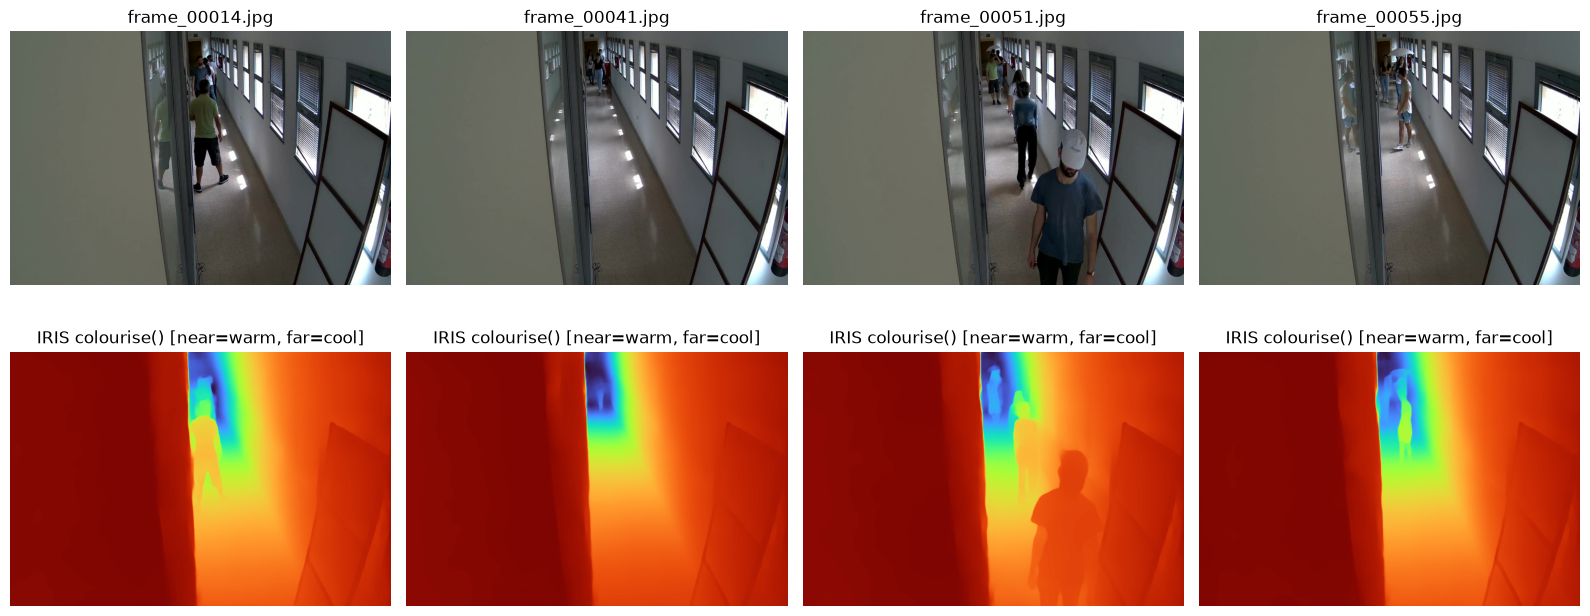


FINAL TASK 4 (DA3-SMALL) VERDICT: ZERO-CODE-EDIT DROP-IN COMPATIBLE with perception/modules/proximity/depth.py!
Note for Proximity tuning: re-calibrate products/proximity zone `depth_max_gap` (default ~0.25 for YOLO26m-depth) against DA3 relative depth scale.


In [4]:
# 1) Drop directly into IRIS DepthModel + ensure_on_gpu
dm = DepthModel(str(ONNX_DA3_PATH))
ensure_on_gpu(dm.session)
print(f"IRIS DepthModel providers: {dm.session.get_providers()} | hw={dm.hw}")

max_abs_errs = []
for name in SAMPLE_NAMES:
    bgr, pt_d, _ = pt_depths[name]
    ort_d, s = dm(bgr)
    err = float(np.max(np.abs(pt_d - ort_d)))
    max_abs_errs.append(err)
    print(f"  {name:15s} | scale={s:.3f} | unpadded={ort_d.shape} | PT vs ORT max_diff={err:.6f}")

assert max(max_abs_errs) < 1e-2, f"Unexpected PT vs ORT depth drift: {max_abs_errs}"

# 2) Real IRIS DepthWorker + depth_gap calibration check on frame_00014.jpg
bgr14, _, _ = pt_depths["frame_00014.jpg"]
d14, _ = dm(bgr14)
H14, W14 = d14.shape  # depth map in letterboxed scale (s * capture)
orig_h, orig_w = bgr14.shape[:2]

# Pick real regions from d14: two horizontally adjacent foreground patches (same-depth) vs foreground vs deep-background
d14_norm = cv2.resize(d14, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
near_y, near_x = np.unravel_index(int(np.argmin(d14_norm[100:orig_h-80, 80:orig_w-80])), (orig_h-180, orig_w-160))
near_x += 80; near_y += 100
far_y, far_x = np.unravel_index(int(np.argmax(d14_norm[40:orig_h-120, 80:orig_w-80])), (orig_h-160, orig_w-160))
far_x += 80; far_y += 40

# Two overlapping/adjacent boxes on the near foreground plane vs near foreground against far corridor point
pw, ph = 60, 80
nx0 = max(10, min(orig_w - pw - 40, near_x - pw // 2))
ny0 = max(10, min(orig_h - ph - 10, near_y - ph // 2))
fx0 = max(10, min(orig_w - pw - 10, far_x - pw // 2))
fy0 = max(10, min(orig_h - ph - 10, far_y - ph // 2))

req_same_plane = DepthRequest(
    ("pair", 1, 2),
    Blob(np.ones((ph, pw), bool), nx0, ny0, 1.0, 1.0), (nx0, ny0, pw, ph),
    Blob(np.ones((ph, pw), bool), nx0 + 10, ny0, 1.0, 1.0), (nx0 + 10, ny0, pw, ph),
)
req_near_vs_far = DepthRequest(
    ("pair", 1, 3),
    Blob(np.ones((ph, pw), bool), nx0, ny0, 1.0, 1.0), (nx0, ny0, pw, ph),
    Blob(np.ones((ph, pw), bool), fx0, fy0, 1.0, 1.0), (fx0, fy0, pw, ph),
)

worker = DepthWorker(lambda: dm)
worker.start()
try:
    scale_mux = dm.hw[1] / orig_w  # mux == capture (1.0) -> dm scale
    assert worker.submit("cam-test", 1.0, bgr14, (1.0, 1.0), [req_same_plane, req_near_vs_far])
    deadline = time.monotonic() + 5.0
    while worker.busy("cam-test") and time.monotonic() < deadline:
        time.sleep(0.01)
    _, gap_near = worker.latest("cam-test", req_same_plane.key)
    _, gap_far = worker.latest("cam-test", req_near_vs_far.key)
    t_map, color_map = worker.latest_map("cam-test")
    print(f"IRIS DepthWorker test: same-plane gap={gap_near:.4f} | near-vs-far gap={gap_far:.4f} | worker failed={worker.failed}")
    assert worker.failed == 0 and gap_far > gap_near
finally:
    worker.stop()

# 3) Full 60-frame GPU latency benchmark through IRIS DepthModel
_ = dm(cv2.imread(str(calib_images[0])))
all_bgrs = [cv2.imread(str(p)) for p in calib_images]
t0 = time.perf_counter()
for b in all_bgrs:
    _ = dm(b)
elapsed = time.perf_counter() - t0
print(f"IRIS DepthModel ORT CUDA (60 frames @ {TARGET_HW[0]}x{TARGET_HW[1]}): {elapsed/len(all_bgrs)*1000:.2f} ms/frame ({len(all_bgrs)/elapsed:.1f} FPS)")

# 4) Render input + IRIS colourise() TURBO depth maps
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for idx, name in enumerate(SAMPLE_NAMES):
    bgr, _, _ = pt_depths[name]
    ort_d, _ = dm(bgr)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    vis_bgr = colourise(ort_d)
    vis_rgb = cv2.cvtColor(vis_bgr, cv2.COLOR_BGR2RGB)
    axes[0, idx].imshow(rgb)
    axes[0, idx].set_title(f"{name}")
    axes[0, idx].axis("off")
    axes[1, idx].imshow(vis_rgb)
    axes[1, idx].set_title(f"IRIS colourise() [near=warm, far=cool]")
    axes[1, idx].axis("off")
plt.tight_layout()
plt.show()

print("\nFINAL TASK 4 (DA3-SMALL) VERDICT: ZERO-CODE-EDIT DROP-IN COMPATIBLE with perception/modules/proximity/depth.py!")
print("Note for Proximity tuning: re-calibrate products/proximity zone `depth_max_gap` (default ~0.25 for YOLO26m-depth) against DA3 relative depth scale.")
